# Análise de 47 milhões de corridas de táxi de NYC com Spark e Dask
## NYC Yellow Taxi (jan/2015 e jan–mar/2016)

**Autora:** Laura Silva Soares de Melo — projeto da pós-graduação em Engenharia e Análise de Dados (CESAR School)

**Tecnologias:** Apache Spark (PySpark) nas perguntas 1, 2 e 4 e Dask na pergunta 3.


## 1. Dados

**Dataset original:** https://www.kaggle.com/datasets/elemento/nyc-yellow-taxi-trip-data
(NYC Yellow Taxi Trip Data, corridas de táxi amarelo de Nova York, ~47 milhões de linhas, ~7,5 GB em CSV.)


**Arquivos utilizados (todos os 4 CSVs do dataset):**

| Arquivo | Período |
|---|---|
| `yellow_tripdata_2015-01.csv` | jan/2015 |
| `yellow_tripdata_2016-01.csv` | jan/2016 |
| `yellow_tripdata_2016-02.csv` | fev/2016 |
| `yellow_tripdata_2016-03.csv` | mar/2016 |

Colunas usadas: horários de embarque/desembarque, distância, coordenadas de embarque, tipo de pagamento, tarifa, gorjeta e valor total.

## 2. Configuração e download

In [1]:
import os, glob, time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, Window
import pyspark.sql.functions as F
from pyspark.sql.types import (StructType, StructField, IntegerType, DoubleType,
                               StringType, TimestampType)

# ---------------------------------------------------------------------------
# Onde estão os CSVs? Ordem de prioridade:
#   1) variável de ambiente DATA_DIR
#   2) DATA_DIR_MANUAL (preencha se baixou o zip do Kaggle na mão e extraiu numa pasta)
#   3) download automático via kagglehub
# ---------------------------------------------------------------------------
DATA_DIR_MANUAL = None   # ex.: r"C:\Users\voce\Downloads\nyc-taxi"

def localizar_dados():
    pasta = os.environ.get("DATA_DIR") or DATA_DIR_MANUAL
    if pasta:
        return pasta
    try:
        # Redes corporativas com inspeção SSL causam "CERTIFICATE_VERIFY_FAILED".
        # truststore faz o Python usar os certificados do sistema operacional (que incluem o da empresa).
        import truststore
        truststore.inject_into_ssl()
    except ImportError:
        pass
    try:
        import kagglehub
        return kagglehub.dataset_download("elemento/nyc-yellow-taxi-trip-data")
    except Exception as e:
        raise RuntimeError(
            "Não foi possível baixar do Kaggle automaticamente: " + str(e)[:200] + "\n\n"
            "Soluções: (a) pip install truststore e rode a célula de novo; "
            "(b) baixe o zip em https://www.kaggle.com/datasets/elemento/nyc-yellow-taxi-trip-data, "
            "extraia e preencha DATA_DIR_MANUAL acima com a pasta dos CSVs."
        ) from e

DATA_DIR = localizar_dados()

CSV_FILES = sorted(glob.glob(os.path.join(DATA_DIR, "**", "yellow_tripdata_*.csv"), recursive=True))
assert CSV_FILES, f"Nenhum yellow_tripdata_*.csv encontrado em {DATA_DIR}"
print("Arquivos encontrados:")
for f in CSV_FILES:
    print(f"  {Path(f).name}  ({Path(f).stat().st_size/1e9:.2f} GB)")

# Onde guardamos os dados limpos (Parquet), reutilizados por Spark e Dask
PARQUET_DIR = os.environ.get("PARQUET_DIR", "nyc_taxi_limpo.parquet")

# Parâmetros das análises
EXCLUIR_DATAS = ["2015-01-26", "2015-01-27"]   # nevasca de jan/2015 (proibição de tráfego em NYC)
MIN_AMOSTRA   = 1000                           # mínimo de corridas por grupo nas análises

Arquivos encontrados:
  yellow_tripdata_2015-01.csv  (1.99 GB)
  yellow_tripdata_2016-01.csv  (1.71 GB)
  yellow_tripdata_2016-02.csv  (1.78 GB)
  yellow_tripdata_2016-03.csv  (1.91 GB)


## 3. Spark, leitura, limpeza e transformação

Decisões para não estourar memória e manter a performance:
- **Schema explícito**: `inferSchema=True` obrigaria o Spark a ler todo o CSV duas vezes.
- **Nenhum `collect()`/`toPandas()` sobre dados grandes**: só resultados já agregados (poucas centenas de linhas) vão para o pandas.
- **Limpeza uma única vez**, gravada em **Parquet** (colunar e comprimido). As perguntas leem o Parquet, e o Dask também.
- O Spark roda em modo local com `shuffle.partitions` reduzido e AQE ligado.

In [2]:
spark = (
    SparkSession.builder
    .appName("TrabalhoBigData-NYCTaxi")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.ansi.enabled", "false")   # divisão por zero vira null em vez de exceção
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

schema = StructType([
    StructField("VendorID", IntegerType()),
    StructField("tpep_pickup_datetime", TimestampType()),
    StructField("tpep_dropoff_datetime", TimestampType()),
    StructField("passenger_count", IntegerType()),
    StructField("trip_distance", DoubleType()),
    StructField("pickup_longitude", DoubleType()),
    StructField("pickup_latitude", DoubleType()),
    StructField("RatecodeID", IntegerType()),
    StructField("store_and_fwd_flag", StringType()),
    StructField("dropoff_longitude", DoubleType()),
    StructField("dropoff_latitude", DoubleType()),
    StructField("payment_type", IntegerType()),
    StructField("fare_amount", DoubleType()),
    StructField("extra", DoubleType()),
    StructField("mta_tax", DoubleType()),
    StructField("tip_amount", DoubleType()),
    StructField("tolls_amount", DoubleType()),
    StructField("improvement_surcharge", DoubleType()),
    StructField("total_amount", DoubleType()),
])

raw = (
    spark.read
    .option("header", True)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(schema)
    .csv(CSV_FILES)
)
raw.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)



In [3]:
pick, drop = F.col("tpep_pickup_datetime"), F.col("tpep_dropoff_datetime")

# Caixa aproximada da cidade de Nova York (descarta coordenadas 0,0 e fora da cidade)
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 40.49, 40.92, -74.27, -73.68

limpo = (
    raw
    .withColumn("data", F.to_date(pick))
    .withColumn("ano", F.year(pick))
    .withColumn("mes", F.month(pick))
    .withColumn("duracao_min", (F.unix_timestamp(drop) - F.unix_timestamp(pick)) / 60)
    # Timestamps errados existem no dataset: mantém só os meses que os arquivos deveriam ter
    .filter(((F.col("ano") == 2015) & (F.col("mes") == 1)) |
            ((F.col("ano") == 2016) & F.col("mes").isin(1, 2, 3)))
    .filter(F.col("duracao_min").between(1, 180))
    .filter(F.col("trip_distance").between(0.1, 100))
    .filter(F.col("fare_amount").between(2.5, 500))
    .filter(F.col("total_amount").between(3, 600))
    .filter(F.col("tip_amount").between(0, 200))
    .filter(F.col("passenger_count").between(1, 6))
    .filter(F.col("pickup_latitude").between(LAT_MIN, LAT_MAX))
    .filter(F.col("pickup_longitude").between(LON_MIN, LON_MAX))
    .withColumn("velocidade_mph", F.col("trip_distance") / (F.col("duracao_min") / 60))
    .filter(F.col("velocidade_mph") <= 80)
    # ---- variáveis derivadas ----
    .withColumn("hora", F.hour(pick))
    .withColumn("dow", ((F.dayofweek(pick) + 5) % 7) + 1)          # 1=segunda ... 7=domingo
    .withColumn("tipo_dia", F.when(F.col("dow") >= 6, "Fim de semana").otherwise("Dia útil"))
    .withColumn("faixa_dia",
        F.when(F.col("hora") < 6,  "1-Madrugada (0-5h)")
         .when(F.col("hora") < 10, "2-Pico manhã (6-9h)")
         .when(F.col("hora") < 16, "3-Meio do dia (10-15h)")
         .when(F.col("hora") < 20, "4-Pico tarde (16-19h)")
         .otherwise("5-Noite (20-23h)"))
    .withColumn("faixa_dist",
        F.when(F.col("trip_distance") < 1, "a) < 1 mi")
         .when(F.col("trip_distance") < 3, "b) 1-3 mi")
         .when(F.col("trip_distance") < 7, "c) 3-7 mi")
         .otherwise("d) 7+ mi"))
    .withColumn("gorjeta_pct", F.col("tip_amount") / F.col("fare_amount") * 100)
    # célula de ~1 km x ~0,85 km (0,01 grau) para análise espacial sem shapefile
    .withColumn("cell_lat", F.round(F.floor(F.col("pickup_latitude") / 0.01) * 0.01 + 0.005, 3))
    .withColumn("cell_lon", F.round(F.floor(F.col("pickup_longitude") / 0.01) * 0.01 + 0.005, 3))
    .select("data", "ano", "mes", "hora", "dow", "tipo_dia", "faixa_dia", "faixa_dist",
            "payment_type", "passenger_count", "trip_distance", "duracao_min", "velocidade_mph",
            "fare_amount", "tip_amount", "total_amount", "gorjeta_pct", "cell_lat", "cell_lon")
)

t0 = time.time()
limpo.write.mode("overwrite").parquet(PARQUET_DIR)
print(f"Parquet limpo gravado em '{PARQUET_DIR}' em {time.time()-t0:.0f}s")

clean = spark.read.parquet(PARQUET_DIR)
n_limpo = clean.count()
n_bruto = raw.count()
print(f"Linhas brutas : {n_bruto:,}")
print(f"Linhas limpas : {n_limpo:,}  ({n_limpo/n_bruto:.1%} mantidas, {n_bruto-n_limpo:,} descartadas)")

Parquet limpo gravado em 'nyc_taxi_limpo.parquet' em 385s
Linhas brutas : 47,248,845
Linhas limpas : 45,994,800  (97.3% mantidas, 1,254,045 descartadas)


## 4. Perguntas e respostas

### Pergunta 1 (Spark): O volume de corridas caiu de jan/2015 para jan/2016 e em quais horários da semana a queda foi mais forte?

**Hipótese:** a expansão de aplicativos de transporte (Uber, Lyft, Via) tirou corridas do táxi, principalmente à noite e nos fins de semana, enquanto o horário comercial ficou mais estável.

**Método:** para cada combinação *dia da semana × hora* contamos as corridas por ano e dividimos pelo **número de dias daquele dia da semana** no mês (jan/2015 e jan/2016 têm quantidades diferentes de cada dia da semana, e comparar contagens brutas distorceria o resultado). Os dias da nevasca de 2015 ficam fora. Usamos `join` com tabela pequena (broadcast), `pivot` e função de janela para ranquear.

Corridas por dia (média, jan/2015): 2,866,878
Corridas por dia (média, jan/2016): 2,404,215
Variação total: -16.14%

10 janelas (dia × hora) com maior variação negativa:


,dia,hora,jan_2015,jan_2016,var_pct
0,Qui,3,6712.8,2314.8,-65.5
1,Qui,2,8399.8,3493.5,-58.4
2,Qui,4,5183.4,2216.0,-57.2
3,Qui,1,11040.2,5514.2,-50.0
4,Sáb,19,28878.2,18911.4,-34.5
5,Sáb,20,24659.6,16203.4,-34.3
6,Sáb,22,26781.0,17626.2,-34.2
7,Sáb,21,24280.8,16001.8,-34.1
8,Sáb,23,27535.6,18179.2,-34.0
9,Sáb,18,27824.4,18598.8,-33.2


10 janelas com maior variação positiva:


,dia,hora,jan_2015,jan_2016,var_pct
167,Sex,3,3775.8,6952.2,84.1
166,Sex,4,3178.6,5436.6,71.0
165,Sex,2,5621.0,9211.6,63.9
164,Sex,1,8464.8,12054.2,42.4
163,Sex,5,3957.4,4626.0,16.9
162,Sex,0,13617.0,15222.8,11.8
161,Qui,7,18222.2,18445.2,1.2
160,Qui,8,21235.4,21420.5,0.9
159,Qui,9,19897.6,19622.0,-1.4
158,Qui,6,10539.0,10236.8,-2.9


Variação por tipo de dia e faixa do dia:


jan_2015  jan_2016  var_pct
tipo          faixa                                   
Dia útil      Madrugada    165124.0  146192.6    -11.5
              Pico manhã   358267.7  320914.9    -10.4
              Meio do dia  583166.4  511702.3    -12.2
              Pico tarde   463200.6  409950.3    -11.5
              Noite        450574.3  392017.1    -13.0
Fim de semana Madrugada    175140.0  130125.6    -25.7
              Pico manhã    66724.0   48078.6    -27.9
              Meio do dia  259967.2  189413.4    -27.1
              Pico tarde   183400.5  138635.8    -24.4
              Noite        161312.8  117184.0    -27.4

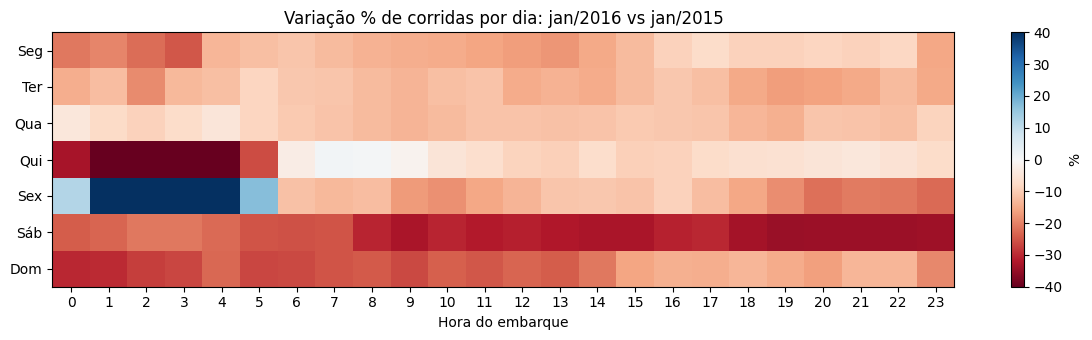

In [4]:
DIAS = {1: "Seg", 2: "Ter", 3: "Qua", 4: "Qui", 5: "Sex", 6: "Sáb", 7: "Dom"}

jan = (clean.filter(F.col("mes") == 1)
            .filter(~F.col("data").cast("string").isin(EXCLUIR_DATAS)))

# nº de dias distintos de cada dia da semana em cada ano (tabela minúscula -> broadcast)
n_dias = jan.groupBy("ano", "dow").agg(F.countDistinct("data").alias("n_dias"))

p1 = (jan.groupBy("ano", "dow", "hora").agg(F.count("*").alias("corridas"))
         .join(F.broadcast(n_dias), ["ano", "dow"])
         .withColumn("corridas_por_dia", F.col("corridas") / F.col("n_dias"))
         .groupBy("dow", "hora").pivot("ano", [2015, 2016]).agg(F.first("corridas_por_dia"))
         .withColumnRenamed("2015", "jan_2015")
         .withColumnRenamed("2016", "jan_2016")
         .withColumn("var_pct", F.round((F.col("jan_2016") - F.col("jan_2015")) / F.col("jan_2015") * 100, 2))
         .withColumn("ranking_queda", F.row_number().over(Window.orderBy("var_pct")))  # 168 linhas: janela global é barata
)

p1_pdf = p1.orderBy("ranking_queda").toPandas()          # só 168 linhas
p1_pdf["dia"] = p1_pdf["dow"].map(DIAS)

tot = p1_pdf[["jan_2015", "jan_2016"]].sum()
print(f"Corridas por dia (média, jan/2015): {tot['jan_2015']:,.0f}")
print(f"Corridas por dia (média, jan/2016): {tot['jan_2016']:,.0f}")
print(f"Variação total: {(tot['jan_2016']/tot['jan_2015']-1)*100:+.2f}%\n")

print("10 janelas (dia × hora) com maior variação negativa:")
display(p1_pdf.head(10)[["dia", "hora", "jan_2015", "jan_2016", "var_pct"]].round(1))
print("10 janelas com maior variação positiva:")
display(p1_pdf.tail(10).iloc[::-1][["dia", "hora", "jan_2015", "jan_2016", "var_pct"]].round(1))

# variação por faixa do dia (ponderada pelo volume, não média simples de percentuais)
p1_pdf["faixa"] = pd.cut(p1_pdf["hora"], [-1, 5, 9, 15, 19, 23],
                         labels=["Madrugada", "Pico manhã", "Meio do dia", "Pico tarde", "Noite"])
p1_pdf["tipo"] = p1_pdf["dow"].map(lambda d: "Fim de semana" if d >= 6 else "Dia útil")
resumo = p1_pdf.groupby(["tipo", "faixa"], observed=True)[["jan_2015", "jan_2016"]].sum()
resumo["var_pct"] = ((resumo["jan_2016"] / resumo["jan_2015"] - 1) * 100).round(2)
print("Variação por tipo de dia e faixa do dia:")
display(resumo.round(1))

heat = p1_pdf.pivot(index="dow", columns="hora", values="var_pct").rename(index=DIAS)
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat.values, aspect="auto", cmap="RdBu", vmin=-40, vmax=40)
ax.set_yticks(range(7)); ax.set_yticklabels(heat.index)
ax.set_xticks(range(24)); ax.set_xlabel("Hora do embarque")
ax.set_title("Variação % de corridas por dia: jan/2016 vs jan/2015")
fig.colorbar(im, label="%"); plt.tight_layout(); plt.show()

**Conclusão da pergunta 1** — hipótese **confirmada**, com uma ressalva.

- O volume médio diário caiu de **2,87 milhões para 2,40 milhões de corridas (−16,1%)** entre jan/2015 e jan/2016.
- A queda foi **cerca do dobro nos fins de semana** (cerca de −24% a −28% em todas as faixas do dia) do que nos dias úteis (cerca de −10% a −13%). Ou seja, o horário comercial de dia útil ficou mais estável, como previsto.
- As maiores quedas por janela foram **quinta-feira de madrugada (1h–4h, de −50% a −65%)** e **sábado à noite (18h–23h, cerca de −34%)**, o que combina com a hipótese de que o uso noturno e de lazer foi o que mais migrou.
- **Ressalva:** as sextas de madrugada (1h–5h) tiveram o movimento oposto, com aumentos de +17% a +84%. Um padrão simétrico (quinta cai, sexta sobe) sugere possível efeito de calendário ou de registro dos horários, e não demanda real. Não testamos isso, então vale investigar antes de tirar conclusões sobre essas janelas.
- Os dados mostram um padrão **compatível** com a hipótese dos aplicativos de transporte, mas não provam a causa: não há variável de concorrência no dataset.

### Pergunta 2 (Spark): Entre corridas pagas com cartão, o percentual de gorjeta muda conforme dia da semana, faixa do dia e distância? Em cada faixa de distância, qual combinação gera a maior gorjeta?

**Hipótese:** passageiros dão gorjetas percentualmente maiores em corridas curtas (valor mínimo) e à noite/fim de semana (lazer) do que nos horários de pico em dias úteis (deslocamento de trabalho).

**Método:** consideramos apenas `payment_type = 1` (cartão), porque gorjetas em dinheiro **não são registradas** no dataset e viesariam tudo para zero. Calculamos média, mediana e P90 (`percentile_approx`, que não exige ordenar tudo) e a fração de corridas sem gorjeta. Depois usamos função de janela para ranquear as combinações dentro de cada faixa de distância.

In [5]:
cartao = clean.filter(F.col("payment_type") == 1)

p2 = (cartao.groupBy("faixa_dist", "tipo_dia", "faixa_dia")
      .agg(F.count("*").alias("corridas"),
           F.round(F.avg("gorjeta_pct"), 2).alias("gorjeta_media_pct"),
           F.round(F.percentile_approx("gorjeta_pct", 0.5), 2).alias("mediana_pct"),
           F.round(F.percentile_approx("gorjeta_pct", 0.9), 2).alias("p90_pct"),
           F.round(F.avg((F.col("tip_amount") == 0).cast("int")) * 100, 2).alias("sem_gorjeta_pct"),
           F.round(F.avg("fare_amount"), 2).alias("tarifa_media"))
      .filter(F.col("corridas") >= MIN_AMOSTRA)               # evita conclusões com amostra minúscula
      .withColumn("rank_na_distancia",
                  F.row_number().over(Window.partitionBy("faixa_dist").orderBy(F.desc("gorjeta_media_pct"))))
)

p2_pdf = p2.orderBy("faixa_dist", "rank_na_distancia").toPandas()      # no máx. 40 linhas

print("Melhor combinação (maior gorjeta média) em cada faixa de distância:")
display(p2_pdf[p2_pdf["rank_na_distancia"] == 1].drop(columns="rank_na_distancia"))

print("Visão geral: gorjeta média (%) por faixa do dia × tipo de dia")
display(p2_pdf.pivot_table(index="faixa_dia", columns="tipo_dia", values="gorjeta_media_pct", aggfunc="mean").round(2))

print("Visão geral: gorjeta média (%) por faixa de distância")
display(p2_pdf.groupby("faixa_dist")["gorjeta_media_pct"].mean().round(2).to_frame())

Melhor combinação (maior gorjeta média) em cada faixa de distância:


,faixa_dist,tipo_dia,faixa_dia,corridas,gorjeta_media_pct,mediana_pct,p90_pct,sem_gorjeta_pct,tarifa_media
0,a) < 1 mi,Dia útil,1-Madrugada (0-5h),234253,26.37,25.20,37.09,6.52,4.89
10,b) 1-3 mi,Dia útil,4-Pico tarde (16-19h),2643926,21.98,23.27,30.00,2.66,9.57
20,c) 3-7 mi,Dia útil,5-Noite (20-23h),1229594,19.79,21.41,27.10,2.80,16.96
30,d) 7+ mi,Dia útil,4-Pico tarde (16-19h),432293,21.15,22.31,30.19,4.28,38.92


Visão geral: gorjeta média (%) por faixa do dia × tipo de dia


tipo_dia,Dia útil,Fim de semana
faixa_dia,,
1-Madrugada (0-5h),21.74,20.63
2-Pico manhã (6-9h),20.32,20.78
3-Meio do dia (10-15h),20.88,20.58
4-Pico tarde (16-19h),22.20,20.56
5-Noite (20-23h),21.71,21.06


Visão geral: gorjeta média (%) por faixa de distância


,gorjeta_media_pct
faixa_dist,
a) < 1 mi,24.51
b) 1-3 mi,20.94
c) 3-7 mi,18.95
d) 7+ mi,19.79


**Conclusão da pergunta 2** — hipótese **parcialmente confirmada**.

- **Confirmada para a distância:** corridas curtas têm gorjeta percentual maior. A média é de **24,5% abaixo de 1 milha**, contra 20,9% (1–3 mi), 19,0% (3–7 mi) e 19,8% (7+ mi). Isso é esperado em parte porque a tarifa mínima é baixa (tarifa média de US$ 4,89 na faixa < 1 mi), então um valor fixo de gorjeta pesa mais em percentual.
- **Refutada para noite e fim de semana:** a gorjeta varia pouco ao longo do dia (de 20,3% a 22,2%) e, na maior parte das faixas, é **ligeiramente maior em dias úteis** do que no fim de semana. A maior média geral foi o **pico da tarde de dia útil (22,2%)**.
- Em todas as quatro faixas de distância, a combinação com maior gorjeta média foi de **dia útil**. A mais alta de todas foi a madrugada de dia útil em corridas < 1 mi (**26,4%**, mas com amostra menor: 234 mil corridas, contra 2,6 milhões em 1–3 mi no pico da tarde).
- **Limite da análise:** só considera pagamentos com cartão (gorjeta em dinheiro não é registrada no dataset).

### Pergunta 3 (Dask): Em quais horários da semana o trânsito é mais lento e a velocidade média piorou de jan/2015 para jan/2016?

**Hipótese:** a velocidade é mínima nos picos de dias úteis (manhã e fim de tarde) e máxima na madrugada, e a velocidade média em jan/2016 é menor que em jan/2015 (mais veículos de aplicativo e obras).

**Método:** a velocidade de cada janela é calculada como **soma das distâncias ÷ soma do tempo** (velocidade agregada), o que evita que corridas muito curtas dominem uma média simples de razões. O Dask lê apenas 5 colunas do Parquet, agrega em paralelo por partição e só traz para a memória a tabela final (ano × mês × dia × hora).

<Client: 'tcp://127.0.0.1:36893' processes=2 threads=4, memory=3.73 GiB>


5 janelas mais LENTAS:


,dia,hora,velocidade_mph,corridas
33,Ter,9,9.76,327146.0
57,Qua,9,9.81,348696.0
81,Qui,9,9.91,360036.0
35,Ter,11,10.07,281521.0
34,Ter,10,10.09,284579.0


5 janelas mais RÁPIDAS:


,dia,hora,velocidade_mph,corridas
53,Qua,5,23.65,63558.0
126,Sáb,6,23.94,76170.0
4,Seg,4,24.06,39681.0
5,Seg,5,24.68,63408.0
150,Dom,6,25.19,61157.0


Velocidade média (mph) por hora, jan/2015 vs jan/2016:


ano,jan_2015,jan_2016,var_pct
hora,,,
0,16.29,15.97,-2.01
1,16.40,16.12,-1.76
2,16.57,16.45,-0.68
3,17.66,17.42,-1.34
4,20.36,19.91,-2.23
5,23.76,23.12,-2.69
6,19.43,18.65,-3.99
7,14.20,13.77,-3.02
8,11.45,11.22,-2.05


Velocidade agregada jan/2015: 13.59 mph | jan/2016: 13.21 mph | variação -2.82%
Janela mais lenta: Ter às 9h (9.76 mph)


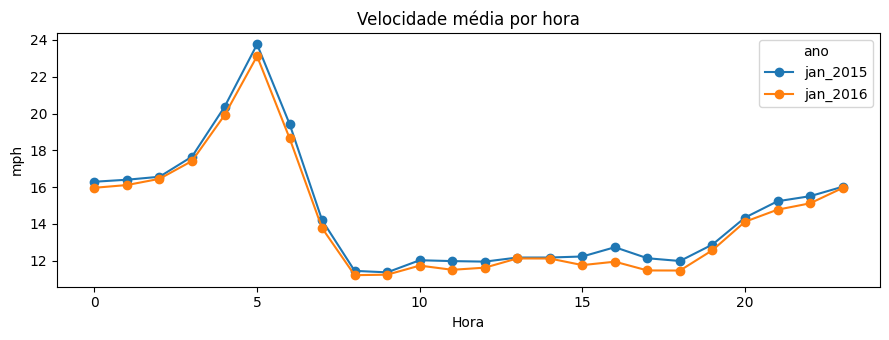

In [6]:
import dask
import dask.dataframe as dd
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=2, threads_per_worker=2,
                       memory_limit=os.environ.get("DASK_WORKER_MEMORY", "2GB"))
client = Client(cluster)
print(client)

ddf = dd.read_parquet(PARQUET_DIR, columns=["ano", "mes", "dow", "hora", "trip_distance", "duracao_min"])
ddf["duracao_h"] = ddf["duracao_min"] / 60

agg = (ddf.groupby(["ano", "mes", "dow", "hora"])
          .agg({"trip_distance": ["sum", "count"], "duracao_h": "sum"})
          .compute())                                   # resultado pequeno: no máx. 4*7*24 linhas
agg.columns = ["dist_mi", "corridas", "horas"]
agg = agg.reset_index()
agg["dow"] = agg["dow"].astype(int); agg["hora"] = agg["hora"].astype(int)

def vel(g):
    return g["dist_mi"].sum() / g["horas"].sum()

# (a) todos os meses juntos: janelas mais lentas e mais rápidas
geral = (agg.groupby(["dow", "hora"])
            .apply(lambda g: pd.Series({"velocidade_mph": vel(g), "corridas": g["corridas"].sum()}),
                   include_groups=False)
            .reset_index())
geral = geral[geral["corridas"] >= MIN_AMOSTRA].sort_values("velocidade_mph")
geral["dia"] = geral["dow"].map(DIAS)
print("5 janelas mais LENTAS:");  display(geral.head(5)[["dia", "hora", "velocidade_mph", "corridas"]].round(2))
print("5 janelas mais RÁPIDAS:"); display(geral.tail(5)[["dia", "hora", "velocidade_mph", "corridas"]].round(2))

# (b) jan/2015 vs jan/2016 por hora do dia
j = agg[agg["mes"] == 1]
por_hora = (j.groupby(["ano", "hora"]).apply(vel, include_groups=False)
              .unstack("ano").rename(columns={2015: "jan_2015", 2016: "jan_2016"}))
por_hora["var_pct"] = (por_hora["jan_2016"] / por_hora["jan_2015"] - 1) * 100
print("Velocidade média (mph) por hora, jan/2015 vs jan/2016:")
display(por_hora.round(2))

g15, g16 = vel(j[j.ano == 2015]), vel(j[j.ano == 2016])
print(f"Velocidade agregada jan/2015: {g15:.2f} mph | jan/2016: {g16:.2f} mph | variação {(g16/g15-1)*100:+.2f}%")
pior = geral.iloc[0]
print(f"Janela mais lenta: {pior['dia']} às {int(pior['hora'])}h ({pior['velocidade_mph']:.2f} mph)")

fig, ax = plt.subplots(figsize=(9, 3.5))
por_hora[["jan_2015", "jan_2016"]].plot(ax=ax, marker="o")
ax.set_ylabel("mph"); ax.set_xlabel("Hora"); ax.set_title("Velocidade média por hora"); plt.tight_layout(); plt.show()

client.close(); cluster.close()

**Conclusão da pergunta 3** — hipótese **confirmada**, com ressalva sobre qual pico é o mais lento.

- A **velocidade agregada caiu de 13,59 mph para 13,21 mph (−2,82%)** entre jan/2015 e jan/2016, e a velocidade média caiu em **todas as 24 horas do dia**.
- As janelas mais lentas são em dias úteis: **terça às 9h (9,76 mph)**, quarta às 9h (9,81) e quinta às 9h (9,91). O trânsito é mais lento pela **manhã e meio da manhã (9h–11h)** do que no pico da tarde, onde a velocidade fica em torno de 12 mph.
- As mais rápidas são de madrugada/início da manhã: **domingo às 6h (25,19 mph)** e segunda às 5h (24,68), como previsto.
- A **piora mais forte foi no fim da tarde**: −6,2% às 16h e −5,5% às 17h. Portanto, o pico da tarde, embora não seja o mais lento em valor absoluto, é onde o trânsito mais se deteriorou.
- Os dados não permitem separar a causa (mais veículos de aplicativo, obras ou outros fatores).

### Pergunta 4 (Spark): Onde a demanda é mais concentrada em cada faixa do dia, e essas regiões são as mais rentáveis por minuto?

**Hipótese:** poucas células de ~1 km concentram uma fração desproporcional dos embarques (Midtown/Downtown Manhattan) em todos os períodos. Porém, as regiões mais rentáveis por minuto de corrida são as de longas distâncias (aeroportos), que não são as mais demandadas.

**Método:** dividimos a cidade em uma grade de 0,01° (≈1 km) a partir das coordenadas de embarque, agregamos por *faixa do dia × célula* e usamos funções de janela para: (i) ranquear as células, (ii) calcular a participação de cada uma no total da faixa, e (iii) acumular a participação das top-N. Também marcamos células nas caixas dos aeroportos JFK e LaGuardia para testar a segunda parte da hipótese.

In [7]:
por_celula = (clean.groupBy("faixa_dia", "cell_lat", "cell_lon")
              .agg(F.count("*").alias("corridas"),
                   F.sum("total_amount").alias("receita"),
                   F.sum("duracao_min").alias("minutos"),
                   F.avg("trip_distance").alias("dist_media_mi"),
                   F.avg("total_amount").alias("ticket_medio")))

w_faixa = Window.partitionBy("faixa_dia")
w_rank  = w_faixa.orderBy(F.desc("corridas"))

p4 = (por_celula
      .withColumn("corridas_faixa", F.sum("corridas").over(w_faixa))
      .withColumn("rank", F.row_number().over(w_rank))
      .withColumn("part_pct", F.col("corridas") / F.col("corridas_faixa") * 100)
      .withColumn("part_acum_pct",
                  F.sum("part_pct").over(w_rank.rowsBetween(Window.unboundedPreceding, Window.currentRow)))
      .withColumn("receita_por_min", F.col("receita") / F.col("minutos"))
      .withColumn("aeroporto",
          F.when(F.col("cell_lat").between(40.62, 40.67) & F.col("cell_lon").between(-73.83, -73.75), "JFK")
           .when(F.col("cell_lat").between(40.76, 40.79) & F.col("cell_lon").between(-73.90, -73.85), "LaGuardia")
           .otherwise("-"))
      .filter(F.col("rank") <= 10)
      .select("faixa_dia", "rank", "cell_lat", "cell_lon", "corridas", "part_pct", "part_acum_pct",
              "receita_por_min", "ticket_medio", "dist_media_mi", "aeroporto")
      .orderBy("faixa_dia", "rank")
)
p4_pdf = p4.toPandas()                               # 5 faixas × 10 células = 50 linhas
cols = ["rank", "cell_lat", "cell_lon", "corridas", "part_pct", "part_acum_pct", "receita_por_min", "ticket_medio", "aeroporto"]
for faixa, g in p4_pdf.groupby("faixa_dia"):
    print(f"\n== {faixa} ==")
    display(g[cols].round(2).reset_index(drop=True))

print("\nParticipação acumulada das 10 células mais demandadas em cada faixa:")
display(p4_pdf.groupby("faixa_dia")["part_acum_pct"].max().round(2).to_frame("top10_%_dos_embarques"))

# Teste da 2ª parte da hipótese: receita por minuto de aeroportos vs. células mais demandadas
aeroportos = (por_celula.filter(F.col("cell_lat").between(40.62, 40.67) & F.col("cell_lon").between(-73.83, -73.75) |
                                F.col("cell_lat").between(40.76, 40.79) & F.col("cell_lon").between(-73.90, -73.85))
                        .agg(F.sum("receita").alias("r"), F.sum("minutos").alias("m"), F.sum("corridas").alias("c")).first())
media_top10 = p4_pdf["receita_por_min"].mean()
if aeroportos["m"]:
    print(f"Receita/min nas células dos aeroportos: US$ {aeroportos['r']/aeroportos['m']:.2f} "
          f"({aeroportos['c']:,} corridas) | média nas top-10 células por faixa: US$ {media_top10:.2f}")


== 1-Madrugada (0-5h) ==


,rank,cell_lat,cell_lon,corridas,part_pct,part_acum_pct,receita_por_min,ticket_medio,aeroporto
0,1,40.72,-73.98,384895,7.19,7.19,1.25,16.02,-
1,2,40.72,-74.00,302411,5.65,12.85,1.24,15.11,-
2,3,40.74,-74.00,293525,5.49,18.33,1.23,15.77,-
3,4,40.76,-73.98,284923,5.33,23.66,1.33,16.29,-
4,5,40.74,-73.98,276851,5.18,28.84,1.33,15.29,-
5,6,40.74,-73.98,265220,4.96,33.79,1.32,14.76,-
6,7,40.76,-73.98,248288,4.64,38.44,1.36,16.52,-
7,8,40.74,-74.00,246751,4.61,43.05,1.23,15.35,-
8,9,40.76,-73.97,185853,3.47,46.52,1.47,15.85,-
9,10,40.74,-74.00,184380,3.45,49.97,1.32,15.59,-



== 2-Pico manhã (6-9h) ==


,rank,cell_lat,cell_lon,corridas,part_pct,part_acum_pct,receita_por_min,ticket_medio,aeroporto
0,1,40.76,-74.00,413050,5.95,5.95,1.08,11.45,-
1,2,40.76,-73.97,376074,5.42,11.37,1.17,13.03,-
2,3,40.78,-73.96,320672,4.62,15.99,1.13,13.44,-
3,4,40.76,-73.96,319630,4.61,20.60,1.12,11.26,-
4,5,40.74,-74.00,300812,4.33,24.93,1.14,11.62,-
5,6,40.74,-73.98,289020,4.16,29.10,1.18,12.05,-
6,7,40.76,-73.98,271176,3.91,33.00,1.16,13.56,-
7,8,40.76,-73.98,249796,3.60,36.60,1.22,13.82,-
8,9,40.74,-73.97,240583,3.47,40.07,1.20,12.72,-
9,10,40.74,-73.98,238488,3.44,43.51,1.17,12.79,-



== 3-Meio do dia (10-15h) ==


...


== 5-Noite (20-23h) ==


,rank,cell_lat,cell_lon,corridas,part_pct,part_acum_pct,receita_por_min,ticket_medio,aeroporto
0,1,40.76,-73.97,671939,6.77,6.77,1.23,14.37,-
1,2,40.76,-73.98,556849,5.61,12.39,1.17,13.90,-
2,3,40.74,-73.98,546615,5.51,17.90,1.18,13.77,-
3,4,40.76,-73.98,531270,5.36,23.25,1.18,14.10,-
4,5,40.74,-73.98,416255,4.20,27.45,1.16,13.51,-
5,6,40.74,-74.00,413613,4.17,31.62,1.17,13.73,-
6,7,40.72,-74.00,399533,4.03,35.64,1.13,14.53,-
7,8,40.76,-73.97,390672,3.94,39.58,1.18,13.48,-
8,9,40.76,-74.00,379552,3.83,43.41,1.17,14.58,-
9,10,40.74,-74.00,351787,3.55,46.95,1.12,14.34,-



Participação acumulada das 10 células mais demandadas em cada faixa:


,top10_%_dos_embarques
faixa_dia,
1-Madrugada (0-5h),49.97
2-Pico manhã (6-9h),43.51
3-Meio do dia (10-15h),45.63
4-Pico tarde (16-19h),45.81
5-Noite (20-23h),46.95


Receita/min nas células dos aeroportos: US$ 1.47 (2,010,927 corridas) | média nas top-10 células por faixa: US$ 1.15


**Conclusão da pergunta 4** — hipótese **confirmada** nas duas partes.

- **Concentração:** as 10 células de ~1 km mais demandadas concentram **entre 43,5% (pico da manhã) e 50,0% (madrugada)** de todos os embarques da faixa do dia. A célula mais demandada no meio do dia, no pico da tarde e à noite é a mesma, na região de Midtown (lat 40,76 / lon −73,97); no pico da manhã e na madrugada o topo muda para outras células de Manhattan.
- **Rentabilidade:** nenhuma das 10 células mais demandadas de cada faixa é de aeroporto. As células de aeroportos (JFK e LaGuardia) rendem **US$ 1,47 por minuto**, contra **US$ 1,15** de média nas top-10 de demanda (**cerca de 28% mais**), com mais de **2 milhões de corridas** (cerca de 4,4% do total limpo).
- Conclusão prática: a demanda está muito concentrada em Manhattan, mas o retorno por minuto é maior nas corridas longas de aeroporto. Alta demanda e alta rentabilidade não coincidem.

## 5. Encerramento

In [8]:
spark.stop()

### Observações sobre performance e memória
- Os CSVs (~7,5 GB) são lidos **uma vez** com schema explícito, limpos e gravados em Parquet. Todas as perguntas consomem o Parquet, que é menor e permite ler apenas as colunas necessárias.
- Nenhuma etapa carrega o dataset inteiro na memória do driver: apenas resultados agregados (≤ 200 linhas) são convertidos em pandas.
- Agregações usam `count/sum/avg/percentile_approx` (parciais e distribuídas), `broadcast join` para a tabela minúscula de dias e funções de janela particionadas.
- O Dask usa `LocalCluster` com limite de memória por worker, então uma partição grande gera *spill* em disco e não derruba o kernel.
- Parâmetros ajustáveis por variável de ambiente: `SPARK_DRIVER_MEMORY`, `DASK_WORKER_MEMORY`, `DATA_DIR`, `PARQUET_DIR`.